# Exercise 04a

In this exercise, you will use hourly data from the Seoul Bike Sharing Demand dataset to predict the number of bikes rented in each hour.

The following cells display the raw data and divide the observations into training, validation, and test sets. The target is standardised using the mean and standard deviation of the training set. Before interpreting predictions or calculating evaluation metrics, convert the predicted values back to bikes per hour.

Implement each neural network as an `nn.Module`, following the approach used in the tutorial. Define the layers in `__init__` and specify the flow of data in `forward`. Ensure that the output dimension of each layer matches the input dimension of the next.

You are responsible for choosing the network architectures and training settings. In Question 1, you will compare candidate networks on the validation set. In Question 2, you will evaluate the best candidates on the test set and compare them with linear regression, ridge regression, and lasso regression.


## Open this notebook

- **Colab.** Replace `github.com` with `githubtocolab.com` in the repository URL, then open this file. Run the setup cell so Colab can see `seoul_bike.csv`.
- **On your own computer.** Open this file from the `04 Artificial neural networks` folder, so `seoul_bike.csv` sits beside the notebook.


In [1]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "04 Artificial neural networks"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    os.chdir(repo / LESSON_DIR)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/04 Artificial neural networks


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds the table, Matplotlib draws the figures, scikit-learn scales the columns and scores the predictions, and PyTorch builds the network.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("torch", torch.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
scikit-learn 1.7.2
torch 2.5.0
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After it finishes, restart the kernel and run the cells above again.


In [3]:
%pip install numpy pandas matplotlib scikit-learn torch torchinfo


Note: you may need to restart the kernel to use updated packages.


## The bike counts

`seoul_bike.csv` is Seoul Bike Sharing Demand, UCI Machine Learning Repository, https://doi.org/10.24432/C5F62R, CC BY 4.0. `rented` is the hourly count. The inputs are the hour, the weather, the season, the holiday flag, and whether the system was open. The dew point is left out.

The hours are sorted by date, then by hour. The first 50% of the dates are the training set, 1 December 2017 through 31 May 2018. The next 25% are the validation set, 1 June 2018 through 30 August 2018. The last 25% are the test set, 31 August 2018 through 30 November 2018. Every hour of a date stays in one set.

The training dates are winter and spring. A summer hour has 0 in both season columns from the training table, and the temperature carries how warm the hour is. `StandardScaler` is fit on the training hours only. The training counts set `y_mean` and `y_std`. `shuffle=True` in a training loader mixes only those training hours.

`test_hours` holds the date, the hour, and the rented count for each test row, in the same order as `X_test`. The `*_np` arrays are the same numbers, for a scikit-learn model later.


## What the hours look like

The next cell prints the first rows. The left figure shows how many hours fall at each count. The right figure is the average count at each hour of the day: low in the night, higher at the morning commute, highest in the evening.


rows 8760
columns ['date', 'rented', 'hour', 'temperature_c', 'humidity_pct', 'wind_ms', 'visibility_10m', 'dew_c', 'solar_mj', 'rainfall_mm', 'snowfall_cm', 'season', 'holiday', 'functioning']
         date  rented  hour  temperature_c  humidity_pct  wind_ms  visibility_10m  dew_c  solar_mj  rainfall_mm  snowfall_cm  season     holiday functioning
0  01/12/2017     254     0           -5.2            37      2.2            2000  -17.6       0.0          0.0          0.0  Winter  No Holiday         Yes
1  01/12/2017     204     1           -5.5            38      0.8            2000  -17.6       0.0          0.0          0.0  Winter  No Holiday         Yes
2  01/12/2017     173     2           -6.0            39      1.0            2000  -17.7       0.0          0.0          0.0  Winter  No Holiday         Yes
3  01/12/2017     107     3           -6.2            40      0.9            2000  -17.6       0.0          0.0          0.0  Winter  No Holiday         Yes
4  01/12/2017      78

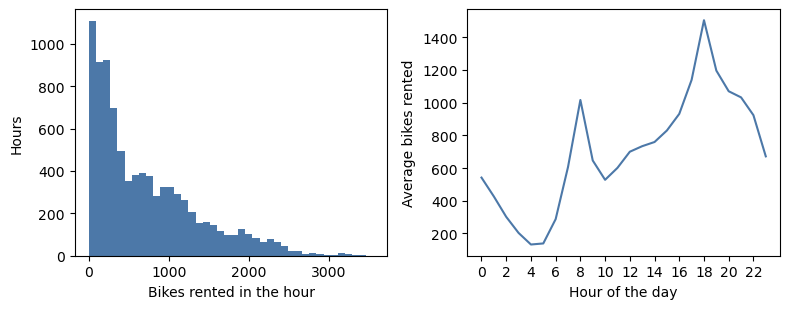

In [4]:
bike = pd.read_csv("seoul_bike.csv")
print("rows", len(bike))
print("columns", list(bike.columns))
print(bike.head().to_string())
print(bike[["rented", "temperature_c", "humidity_pct", "rainfall_mm"]].describe().round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
axes[0].hist(bike["rented"], bins=40, color="#4C78A8")
axes[0].set_xlabel("Bikes rented in the hour")
axes[0].set_ylabel("Hours")
by_hour = bike.groupby("hour")["rented"].mean()
axes[1].plot(by_hour.index, by_hour.values, color="#4C78A8")
axes[1].set_xlabel("Hour of the day")
axes[1].set_ylabel("Average bikes rented")
axes[1].set_xticks(range(0, 24, 2))
fig.tight_layout()
plt.show()


In [5]:
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler

bike = pd.read_csv("seoul_bike.csv")
bike["day"] = pd.to_datetime(bike["date"], dayfirst=True)
bike = bike.sort_values(["day", "hour"]).reset_index(drop=True)
days = bike["day"].drop_duplicates().tolist()
n_days = len(days)
train_days = days[: int(n_days * 0.50)]
valid_days = days[int(n_days * 0.50) : int(n_days * 0.75)]
test_days = days[int(n_days * 0.75) :]
train = bike[bike["day"].isin(train_days)].copy()
valid = bike[bike["day"].isin(valid_days)].copy()
test = bike[bike["day"].isin(test_days)].copy()
print("training days", train_days[0].date(), "to", train_days[-1].date(), len(train_days))
print("validation days", valid_days[0].date(), "to", valid_days[-1].date(), len(valid_days))
print("test days", test_days[0].date(), "to", test_days[-1].date(), len(test_days))

num = ["hour", "temperature_c", "humidity_pct", "wind_ms", "visibility_10m", "solar_mj", "rainfall_mm", "snowfall_cm"]
cat = ["season", "holiday", "functioning"]
X_train_np = pd.concat([train[num].astype(float), pd.get_dummies(train[cat], dtype=int)], axis=1)
X_valid_np = pd.concat([valid[num].astype(float), pd.get_dummies(valid[cat], dtype=int)], axis=1)
X_test_np = pd.concat([test[num].astype(float), pd.get_dummies(test[cat], dtype=int)], axis=1)
X_valid_np = X_valid_np.reindex(columns=X_train_np.columns, fill_value=0)
X_test_np = X_test_np.reindex(columns=X_train_np.columns, fill_value=0)

scaler = StandardScaler()
X_train_np = scaler.fit_transform(X_train_np).astype("float32")
X_valid_np = scaler.transform(X_valid_np).astype("float32")
X_test_np = scaler.transform(X_test_np).astype("float32")
y_train_np = train["rented"].to_numpy().astype("float32")
y_valid_np = valid["rented"].to_numpy().astype("float32")
y_test_np = test["rented"].to_numpy().astype("float32")
y_mean = float(y_train_np.mean())
y_std = float(y_train_np.std())
test_hours = test[["date", "hour", "rented"]].reset_index(drop=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_train = torch.tensor(X_train_np, dtype=torch.float32).to(device)
X_valid = torch.tensor(X_valid_np, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test_np, dtype=torch.float32).to(device)
y_train = torch.tensor((y_train_np - y_mean) / y_std, dtype=torch.float32).view(-1, 1).to(device)
y_valid = torch.tensor((y_valid_np - y_mean) / y_std, dtype=torch.float32).view(-1, 1).to(device)
y_test = torch.tensor((y_test_np - y_mean) / y_std, dtype=torch.float32).view(-1, 1).to(device)

print("rows", len(train), len(valid), len(test))
print("input columns", X_train_np.shape[1])
print("training mean", round(y_mean, 1), "training std", round(y_std, 1))

print("Input and target shapes")
print("X_train:", tuple(X_train.shape), "y_train:", tuple(y_train.shape))
print("X_valid:", tuple(X_valid.shape), "y_valid:", tuple(y_valid.shape))
print("X_test: ", tuple(X_test.shape), "y_test: ", tuple(y_test.shape))



training days 2017-12-01 to 2018-05-31 182
validation days 2018-06-01 to 2018-08-30 91
test days 2018-08-31 to 2018-11-30 92
rows 4368 2184 2208
input columns 14
training mean 480.6 training std 519.6


### Question 1 — tune the neural network on the validation set

Use the provided chronological training and validation sets. Keep the single-unit output layer and `nn.MSELoss`, and convert predictions back to bikes per hour before calculating errors.

1. Compare at least five network architectures, including both one-hidden-layer and two-hidden-layer networks. First keep the learning rate fixed and plot validation MAE against architecture.
2. Choose a set of learning rates and evaluate **every architecture–learning-rate combination**. Present the results as a table and a two-dimensional heatmap. A suggested grid is architectures `8`, `16`, `32`, `64`, `128`, `32-16`, `64-32`, and `128-64`, crossed with learning rates `0.001`, `0.003`, `0.01`, and `0.03`.
3. Select the setting with the lowest validation MAE. Plot its training and validation loss against epoch, and report validation MAE, RMSE, R2, and MAPE. Calculate MAPE only where the observed count is at least 5.

Do not use the test set while choosing the architecture or learning rate.

### Question 2 — freeze the settings and compare models once on the test set

Use the validation set to select Ridge and Lasso regularisation strengths from a broad logarithmic grid, such as `0.001` through `1000`. Plot validation MAE against `alpha` on a logarithmic horizontal axis.

After fixing all settings, evaluate the selected neural network, linear regression, Ridge, and Lasso **once** on the test set. Report MAE, RMSE, R2, and MAPE in one table. Draw:

- observed versus predicted scatter plots with the exact-agreement and ±20% reference lines;
- a two-week time-series comparison; and
- mean absolute error by hour of day, so that weak time periods are visible.

State which model performs best and describe when its largest errors occur.